In [1]:
!nvidia-smi --query-gpu=name,memory.total,driver_version,compute_cap --format=csv
!nproc; free -g | head -2; df -h /content | tail -1; cat /etc/os-release | grep PRETTY
!TOKEN=$(curl -s 'https://nvcr.io/proxy_auth?scope=repository:hpc/quantum_espresso:pull' | python3 -c 'import sys,json;print(json.load(sys.stdin)["token"])'); curl -s -H "Authorization: Bearer $TOKEN" https://nvcr.io/v2/hpc/quantum_espresso/tags/list | python3 -c 'import sys,json;print(json.load(sys.stdin).get("tags"))'

name, memory.total [MiB], driver_version, compute_cap
NVIDIA A100-SXM4-40GB, 40960 MiB, 580.82.07, 8.0
12
               total        used        free      shared  buff/cache   available
Mem:              83           1          78           0           3          81
overlay         236G   43G  194G  18% /
PRETTY_NAME="Ubuntu 24.04.4 LTS"
['qe-6.8', 'qe-7.0', 'qe-7.1', 'qe-7.3.1', 'qe-gpu-6.6a1', 'sha256-352db5b01c148b061c057a3452df1c72cf7e27ca022e2b4b29a2e3c367f3b883.sbom', 'sha256-352db5b01c148b061c057a3452df1c72cf7e27ca022e2b4b29a2e3c367f3b883.vex', 'sha256-3ec2807d82621d625deca4d0b836467509a5ca9fb46ee844fd995f218354ed7c.sbom', 'sha256-3ec2807d82621d625deca4d0b836467509a5ca9fb46ee844fd995f218354ed7c.vex', 'sha256-47bbba88b08e38ad68ca5619c3e9615d72f563ac4ba43e1246a5ff48aa81eab7.sbom', 'sha256-47bbba88b08e38ad68ca5619c3e9615d72f563ac4ba43e1246a5ff48aa81eab7.vex', 'sha256-6702ec42e497dd21faf291c8104cc580301425a459760a8b392555d90d3e2cfc.sbom', 'sha256-6702ec42e497dd21faf291c8104cc580301

In [2]:
%cd /content
!unzip -o -q qe-snpim.zip && cd qe-snpim && bash setup_qe_gpu.sh 2>&1 | tail -15
!mkdir -p /content/qe-snpim/pseudo && cd /content/qe-snpim/pseudo && for f in Sn.pbe-dn-rrkjus_psl.1.0.0.UPF Cl.pbe-n-rrkjus_psl.1.0.0.UPF O.pbe-n-rrkjus_psl.1.0.0.UPF N.pbe-n-rrkjus_psl.1.0.0.UPF C.pbe-n-rrkjus_psl.1.0.0.UPF H.pbe-rrkjus_psl.1.0.0.UPF; do wget -q https://pseudopotentials.quantum-espresso.org/upf_files/$f && echo "OK $f $(grep -m1 -ioE 'Suggested minimum cutoff for wavefunctions: *[0-9.]+' $f)" || echo "FAIL $f"; done

/content
[1/4] 安装 skopeo（镜像下载工具）
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
[2/4] 下载 NGC 镜像 nvcr.io/hpc/quantum_espresso:qe-7.3.1（约 1~3 分钟）
[3/4] 解压镜像各层
    pw.x: /content/qe_root/usr/local/qe/bin/pw.x
[4/4] 检查
name, memory.total [MiB], driver_version
NVIDIA A100-SXM4-40GB, 40960 MiB, 580.82.07
pw.x 
QE GPU 环境就绪：用法 qe pw.x -in xxx.in > xxx.out
OK Sn.pbe-dn-rrkjus_psl.1.0.0.UPF Suggested minimum cutoff for wavefunctions:  47.
OK Cl.pbe-n-rrkjus_psl.1.0.0.UPF Suggested minimum cutoff for wavefunctions:  45.
OK O.pbe-n-rrkjus_psl.1.0.0.UPF Suggested minimum cutoff for wavefunctions:  47.
OK N.pbe-n-rrkjus_psl.1.0.0.UPF Suggested minimum cutoff for wavefunctions:  44.
OK C.pbe-n-rrkjus_psl.1.0.0.UPF Suggested minimum cutoff for wavefunctions:  40.
OK H.pbe-rrkjus_psl.1.0.0.UPF Suggested minimum cutoff for wavefunctions:  46.


In [3]:
%cd /content/qe-snpim
!OMP_NUM_THREADS=8 setsid nohup bash -c 'date > start_relax.txt; qe pw.x -in 01_relax.in > 01_relax.out 2>&1; date > DONE_relax' > /dev/null 2>&1 &
!sleep 45; head -60 01_relax.out | grep -iE 'Program PWSCF|GPU|MPI|threads|Error|error' ; grep -E 'number of k points|Kohn-Sham states|number of electrons|FFT dimensions|Estimated' 01_relax.out | head; nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv

/content/qe-snpim
utilization.gpu [%], memory.used [MiB]
0 %, 0 MiB


In [4]:
!ls -la /content/qe-snpim | head -30; echo ---; cat /content/qe-snpim/01_relax.out | head -40; echo ---; ps aux | grep -E 'pw.x|ld-linux' | grep -v grep | head; cat /usr/local/bin/qe | cut -c1-300

total 680
drwxr-xr-x 3 root root   4096 Oct 22 10:44 .
drwxr-xr-x 1 root root   4096 Oct 22 10:42 ..
-rw-r--r-- 1 root root   6375 Oct 22 10:30 01_relax.in
-rw-r--r-- 1 root root     44 Oct 22 10:44 01_relax.out
-rw-r--r-- 1 root root    175 Oct 22 10:30 04_projwfc.in
-rw------- 1 root root 615502 Oct 22 10:29 crystal.cif
-rw-r--r-- 1 root root     32 Oct 22 10:44 DONE_relax
-rw-r--r-- 1 root root    847 Oct 22 10:30 header_bands.tmpl
-rw-r--r-- 1 root root    864 Oct 22 10:30 header_nscf.tmpl
-rw-r--r-- 1 root root    851 Oct 22 10:30 header_scf.tmpl
-rw-r--r-- 1 root root   4333 Oct 22 10:31 make_inputs.py
drwxr-xr-x 2 root root   4096 Oct 22 10:42 pseudo
-rw-r--r-- 1 root root   2491 Oct 22 10:30 setup_qe_gpu.sh
-rw-r--r-- 1 root root     32 Oct 22 10:44 start_relax.txt
-rw-r--r-- 1 root root   7986 Oct 22 10:29 structure_Hnorm.xyz
-rw-r--r-- 1 root root   5285 Oct 22 10:29 structure.qe
---
*** stack smashing detected ***: terminated
---
#!/usr/bin/env bash
# 用法：qe pw.x [参数]  /  qe 

In [5]:
import json, glob
m = json.load(open('/content/qe_img/manifest.json'))
cfg = json.load(open('/content/qe_img/' + m['config']['digest'].split(':')[1]))
print('\n'.join(cfg['config'].get('Env', [])))
print(cfg['config'].get('Entrypoint'), cfg['config'].get('Cmd'))
!ls /content/qe_root/usr/local/qe/bin/ /content/qe_root/usr/local/ | head; ls /content/qe_root/lib64/ /content/qe_root/etc/os-release && grep PRETTY /content/qe_root/etc/os-release

PATH=/usr/local/qe/bin:/usr/local/openmpi/bin:/usr/local/ucx/bin:/usr/local/nvidia/bin:/usr/local/cuda/bin:/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin
LD_LIBRARY_PATH=/usr/local/cuda/lib:/usr/local/cuda/lib64:/usr/local/fftw/lib:/opt/nvidia/hpc_sdk/Linux_x86_64/24.7/compilers/lib:
CPATH=/usr/local/knem/include:/usr/local/gdrcopy/include:
LIBRARY_PATH=/usr/local/gdrcopy/lib:
NVIDIA_DRIVER_CAPABILITIES=compute,utility
NVIDIA_REQUIRE_CUDA=cuda>=12.5 brand=unknown,driver>=450,driver<451 brand=nvidia,driver>=450,driver<451 brand=nvidia-rtx,driver>=450,driver<451 brand=tesla,driver>=450,driver<451 brand=titan,driver>=450,driver<451 brand=titanrtx,driver>=450,driver<451 brand=quadro,driver>=450,driver<451 brand=quadrortx,driver>=450,driver<451 brand=unknown,driver>=470,driver<471 brand=nvidia,driver>=470,driver<471 brand=nvidia-rtx,driver>=470,driver<471 brand=tesla,driver>=470,driver<471 brand=titan,driver>=470,driver<471 brand=titanrtx,driver>=470,driver<471 brand=quadro,dr

In [6]:
%%bash
R=/content/qe_root
ls /usr/lib64-nvidia | head -5; ls /dev/nvidia*
mkdir -p $R/proc $R/dev $R/sys $R/work
mount --bind /proc $R/proc && echo BIND_PROC_OK || echo BIND_PROC_FAIL
mount --rbind /dev $R/dev && echo BIND_DEV_OK || echo BIND_DEV_FAIL
mount --bind /sys $R/sys && echo BIND_SYS_OK || echo BIND_SYS_FAIL
mount --bind /content/qe-snpim $R/work && echo BIND_WORK_OK || echo BIND_WORK_FAIL
cp -a /usr/lib64-nvidia/libcuda.so* /usr/lib64-nvidia/libnvidia-ml.so* /usr/lib64-nvidia/libnvidia-ptxjitcompiler.so* /usr/lib64-nvidia/libnvidia-nvvm.so* $R/usr/lib/x86_64-linux-gnu/ 2>&1 | tail -2
chroot $R /sbin/ldconfig && echo LDCONFIG_OK
chroot $R /bin/bash -c 'export LD_LIBRARY_PATH=/usr/local/cuda/lib:/usr/local/cuda/lib64:/usr/local/fftw/lib:/opt/nvidia/hpc_sdk/Linux_x86_64/24.7/compilers/lib; ldd /usr/local/qe/bin/pw.x | grep -iE "not found|cuda|cublas|mpi" | head'

gbm
libcudadebugger.so.1
libcudadebugger.so.580.82.07
libcuda.so
libcuda.so.1
/dev/nvidia0
/dev/nvidiactl
/dev/nvidia-uvm
/dev/nvidia-uvm-tools

/dev/nvidia-caps:
nvidia-cap1
nvidia-cap2
BIND_PROC_OK
BIND_DEV_OK
BIND_SYS_OK
BIND_WORK_OK
LDCONFIG_OK
	liblapack_lp64.so.0 => /opt/nvidia/hpc_sdk/Linux_x86_64/24.7/compilers/lib/liblapack_lp64.so.0 (0x00007f1308e00000)
	libblas_lp64.so.0 => /opt/nvidia/hpc_sdk/Linux_x86_64/24.7/compilers/lib/libblas_lp64.so.0 (0x00007f1306e00000)
	libmpi_usempif08.so.40 => /usr/local/openmpi/lib/libmpi_usempif08.so.40 (0x00007f1309c2b000)
	libmpi_usempi_ignore_tkr.so.40 => /usr/local/openmpi/lib/libmpi_usempi_ignore_tkr.so.40 (0x00007f1309c21000)
	libmpi_mpifh.so.40 => /usr/local/openmpi/lib/libmpi_mpifh.so.40 (0x00007f1309ba5000)
	libmpi.so.40 => /usr/local/openmpi/lib/libmpi.so.40 (0x00007f1306980000)
	libnvhpcwrapcufft.so => /opt/nvidia/hpc_sdk/Linux_x86_64/24.7/compilers/lib/libnvhpcwrapcufft.so (0x00007f1306600000)
	libcufft.so.11 => /usr/local/cuda/lib

/bin/bash: warning: setlocale: LC_ALL: cannot change locale (en_US.UTF-8)
/bin/bash: warning: setlocale: LC_ALL: cannot change locale (en_US.UTF-8)


In [7]:
w = '''#!/usr/bin/env bash
# 用法（在工作目录里）：qe pw.x -in xxx.in > xxx.out
# 通过 chroot 进入 NGC 镜像的文件系统运行，避免和 Colab 自带的 CUDA 13 库冲突
R=/content/qe_root
W=$(pwd)
mkdir -p $R/proc $R/dev $R/sys $R/work
mountpoint -q $R/proc || mount --bind /proc $R/proc
mountpoint -q $R/dev || mount --rbind /dev $R/dev
mountpoint -q $R/sys || mount --bind /sys $R/sys
if mountpoint -q $R/work; then umount $R/work 2>/dev/null; fi
mount --bind "$W" $R/work
exec chroot $R /usr/bin/env -i HOME=/root PATH=/usr/local/qe/bin:/usr/local/openmpi/bin:/usr/local/ucx/bin:/usr/local/cuda/bin:/usr/sbin:/usr/bin:/sbin:/bin LD_LIBRARY_PATH=/usr/local/cuda/lib:/usr/local/cuda/lib64:/usr/local/fftw/lib:/opt/nvidia/hpc_sdk/Linux_x86_64/24.7/compilers/lib OMP_NUM_THREADS=${OMP_NUM_THREADS:-8} OMPI_ALLOW_RUN_AS_ROOT=1 OMPI_ALLOW_RUN_AS_ROOT_CONFIRM=1 UCX_MEMTYPE_CACHE=n /bin/bash -c "cd /work && $*"
'''
open('/usr/local/bin/qe','w').write(w)
import os; os.chmod('/usr/local/bin/qe', 0o755)
%cd /content/qe-snpim
!rm -f DONE_relax 01_relax.out
!setsid nohup bash -c 'date > start_relax.txt; qe pw.x -in 01_relax.in > 01_relax.out 2>&1; date > DONE_relax' > /dev/null 2>&1 &
!sleep 60; grep -iE 'Program PWSCF|GPU|MPI processes|threads|Error|error' 01_relax.out | head; grep -E 'number of k points|Kohn-Sham states|number of electrons|FFT dimensions|Estimated|total cpu time' 01_relax.out | head -12; nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv

/content/qe-snpim
     Program PWSCF v.7.3.1 starts on 22Oct2026 at 10:47: 4 
     Number of MPI processes:                 1
     Threads/MPI process:                     8
     MPI processes distributed on     1 nodes
     Current dimensions of program PWSCF are:
     GPU acceleration is ACTIVE.  1 visible GPUs per MPI rank
     GPU-aware MPI enabled
     GPU used by master process:
     GPU memory used/free/total (MiB): 8687 / 31753 / 40441
     GPU memory used/free/total (MiB): 9713 / 30727 / 40441
     number of electrons       =       364.00
     number of Kohn-Sham states=          182
     number of k points=     8
     Dense  grid:  1161835 G-vectors     FFT dimensions: (  96, 135, 192)
     Smooth grid:   410795 G-vectors     FFT dimensions: (  72,  96, 135)
     Estimated static dynamical RAM per process >       2.35 GB
     Estimated max dynamical RAM per process >       8.10 GB
     total cpu time spent up to now is        9.1 secs
     total cpu time spent up to now is   

In [8]:
# 状态检查（可反复运行）
!cd /content/qe-snpim; cat start_relax.txt; date; ls DONE_* 2>/dev/null; echo 'SCF 迭代次数:' $(grep -c 'iteration #' 01_relax.out) '  离子步(已完成 SCF):' $(grep -c '^!' 01_relax.out); grep -E '^!|Total force|total cpu time' 01_relax.out | tail -6; grep -E 'estimated scf accuracy' 01_relax.out | tail -2; grep -iE 'error|convergence NOT' 01_relax.out | head -3; nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv,noheader

Thu Oct 22 10:47:04 AM UTC 2026
Thu Oct 22 10:48:31 AM UTC 2026
SCF 迭代次数: 18   离子步(已完成 SCF): 1
     total cpu time spent up to now is       68.9 secs
     total cpu time spent up to now is       72.4 secs
     total cpu time spent up to now is       76.4 secs
!    total energy              =   -1535.73110727 Ry
     Total force =     0.298370     Total SCF correction =     0.000061
     total cpu time spent up to now is       80.0 secs
     estimated scf accuracy    <       0.00000001 Ry
     estimated scf accuracy    <          1.1E-09 Ry
     Energy error            =      0.0E+00 Ry
     Gradient error          =      5.8E-02 Ry/Bohr
53 %, 9950 MiB


In [9]:
# 后处理工具（projwfc.x / dos.x / bands.x）：NGC 镜像只含 pw.x，用 conda-forge 的同版本 CPU 版补上
!cd /content && curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xj bin/micromamba && ./bin/micromamba create -q -y -p /content/qecpu -c conda-forge qe=7.3.1 > mamba.log 2>&1; tail -3 mamba.log; ls /content/qecpu/bin | grep -E '^(pw|projwfc|dos|bands)\.x$'

ls: cannot access '/content/qecpu/bin': No such file or directory


In [10]:
!cd /content; ls -la bin mamba.log; head -c 1500 mamba.log; ./bin/micromamba --version

-rw-r--r-- 1 root root    0 Oct 22 10:48 mamba.log

bin:
total 17876
drwxr-xr-x 2 root root     4096 Oct 22 10:48 .
drwxr-xr-x 1 root root     4096 Oct 22 10:48 ..
-rwxrwxr-x 1 root root 18292808 Aug  7 18:10 micromamba
2.9.0


In [11]:
!cd /content && setsid nohup bash -c './bin/micromamba create -y -r /content/mamba -p /content/qecpu -c conda-forge qe=7.3.1 > mamba.log 2>&1; touch DONE_mamba' > /dev/null 2>&1 &
!sleep 50; tail -5 /content/mamba.log; ls /content/DONE_mamba 2>/dev/null

Resolving Environment                                                                     ✔ Done (0.0 sec)
error    libmamba Could not solve for environment specs
    The following package could not be installed
    └─ qe =7.3.1 * does not exist (perhaps a typo or a missing channel).
critical libmamba Could not solve for environment specs
/content/DONE_mamba


In [12]:
!cd /content && ./bin/micromamba search -r /content/mamba -c conda-forge 'qe>=7' 2>&1 | grep -E '^ *qe ' | head -12; apt-cache policy quantum-espresso | head -4

qe 7.6 mpi_openmpi_hb7b15b3_102 (+ 4 builds)
quantum-espresso:
  Installed: (none)
  Candidate: 6.7-2build4
  Version table:


In [13]:
!cd /content && rm -f DONE_mamba && setsid nohup bash -c './bin/micromamba create -y -r /content/mamba -p /content/qecpu -c conda-forge qe=7.6 > mamba.log 2>&1; touch DONE_mamba' > /dev/null 2>&1 &
!chroot /content/qe_root /bin/bash -c 'LD_LIBRARY_PATH=/usr/local/cuda/lib64:/usr/local/fftw/lib:/opt/nvidia/hpc_sdk/Linux_x86_64/24.7/compilers/lib ldd /usr/local/qe/bin/pw.x' | grep -ciE 'hdf5'

/bin/bash: warning: setlocale: LC_ALL: cannot change locale (en_US.UTF-8)
/bin/bash: warning: setlocale: LC_ALL: cannot change locale (en_US.UTF-8)
0


In [14]:
open('/content/status.sh','w').write('''cd /content/qe-snpim
for f in 01_relax 02_scf 03_nscf 05_bands; do [ -f $f.out ] || continue; echo "== $f: SCF 迭代 $(grep -c "iteration #" $f.out) 次，完成 SCF $(grep -c "^!" $f.out) 次"; grep -E "^!|Total force|bfgs converged|End of BFGS|highest occupied|Fermi energy|JOB DONE|PWSCF  .*WALL" $f.out | tail -4; grep -iE "Error|convergence NOT|Maximum CPU time" $f.out | head -2; done
ls /content/qe-snpim/DONE_* /content/DONE_mamba 2>/dev/null | xargs -n1 basename 2>/dev/null | tr "\n" " "; echo
tail -2 /content/mamba.log 2>/dev/null
date; nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv,noheader
''')
!bash /content/status.sh

== 01_relax: SCF 迭代 74 次，完成 SCF 6 次
     Total force =     0.061738     Total SCF correction =     0.000062
     highest occupied level (ev):     0.9797
!    total energy              =   -1535.80704996 Ry
     Total force =     0.049895     Total SCF correction =     0.000013
     Energy error            =      0.0E+00 Ry
     Gradient error          =      5.8E-02 Ry/Bohr
DONE_mamba 
    micromamba run -p /content/qecpu mycommand

Thu Oct 22 10:52:35 AM UTC 2026
60 %, 9950 MiB


In [15]:
%cd /content/qe-snpim
!unzip -o -q /content/qe-post.zip -d /content/qe-snpim && chmod +x run_after_relax.sh && ls run_after_relax.sh plot_results.py
# 结构优化一结束，自动接着跑自洽 / 能带 / 态密度 / PDOS
!setsid nohup bash -c 'while [ ! -f DONE_relax ]; do sleep 30; done; bash run_after_relax.sh > pipeline.log 2>&1' > /dev/null 2>&1 &
!/content/bin/micromamba run -r /content/mamba -p /content/qecpu bash -c 'ls $CONDA_PREFIX/bin | grep -E "^(projwfc|bands|dos)\.x$"; ldd $CONDA_PREFIX/bin/projwfc.x | grep -c hdf5'
!bash /content/status.sh

/content/qe-snpim
plot_results.py  run_after_relax.sh
bands.x
dos.x
projwfc.x
3
== 01_relax: SCF 迭代 105 次，完成 SCF 10 次
     Total force =     0.024265     Total SCF correction =     0.000010
     highest occupied level (ev):     0.9570
!    total energy              =   -1535.81330847 Ry
     Total force =     0.023673     Total SCF correction =     0.000029
     Energy error            =      0.0E+00 Ry
     Gradient error          =      5.8E-02 Ry/Bohr
DONE_mamba 
    micromamba run -p /content/qecpu mycommand

Thu Oct 22 10:55:03 AM UTC 2026
62 %, 9950 MiB


In [16]:
# conda 版 QE 7.6 用 HDF5 存波函数，读不了 NGC 7.3.1 写的 .dat 文件；编译同版本 7.3.1 的 CPU 后处理程序
!setsid nohup bash -c 'set -e && apt-get -qq install -y gfortran libopenblas-dev libfftw3-dev > /dev/null && cd /content && curl -sL https://gitlab.com/QEF/q-e/-/archive/qe-7.3.1/q-e-qe-7.3.1.tar.gz | tar xz && cd /content/q-e-qe-7.3.1 && ./configure --disable-parallel --disable-openmp --with-hdf5=no > /content/qe731_configure.log 2>&1 && make -j4 pp > /content/qe731_make.log 2>&1 && ls -l bin/projwfc.x bin/bands.x ; touch /content/DONE_qe731' > /content/qe731_build.log 2>&1 &
!sleep 20; tail -3 /content/qe731_build.log; ls /content/q-e-qe-7.3.1 2>/dev/null | head -3

In [17]:
import re
p = '/content/qe-snpim/run_after_relax.sh'; s = open(p).read()
s = re.sub(r'^step pdos .*$', 'step pdos  bash -c "while [ ! -f /content/DONE_qe731 ]; do sleep 30; done; /content/q-e-qe-7.3.1/bin/projwfc.x -in 04_projwfc.in > 04_projwfc.out 2>&1 && ls snpim.pdos.pdos_tot"', s, flags=re.M)
open(p, 'w').write(s)
!grep -n 'step pdos' /content/qe-snpim/run_after_relax.sh; tail -3 /content/qe731_build.log; ls /content/q-e-qe-7.3.1 2>/dev/null | head -3; tail -2 /content/qe731_make.log 2>/dev/null

22:step pdos  bash -c "while [ ! -f /content/DONE_qe731 ]; do sleep 30; done; /content/q-e-qe-7.3.1/bin/projwfc.x -in 04_projwfc.in > 04_projwfc.out 2>&1 && ls snpim.pdos.pdos_tot"


In [18]:
!bash /content/status.sh; echo ---build---; cat /content/qe731_build.log | tail -3; ls /content/q-e-qe-7.3.1 2>/dev/null | wc -l; tail -c 300 /content/qe731_configure.log 2>/dev/null; tail -2 /content/qe731_make.log 2>/dev/null; ls /content/DONE_qe731 2>/dev/null

== 01_relax: SCF 迭代 138 次，完成 SCF 13 次
     Total force =     0.016350     Total SCF correction =     0.000021
     highest occupied level (ev):     0.9667
!    total energy              =   -1535.81438748 Ry
     Total force =     0.019099     Total SCF correction =     0.000022
     Energy error            =      0.0E+00 Ry
     Gradient error          =      5.8E-02 Ry/Bohr
DONE_mamba 
    micromamba run -p /content/qecpu mycommand

Thu Oct 22 10:57:35 AM UTC 2026
59 %, 9950 MiB
---build---
46
ch and retry, as follows:
  ./configure LIBDIRS="list of directories, separated by spaces"

Configured for compilation of serial executables.

For more info, read the ESPRESSO User's Guide (Doc/users-guide.tex).
--------------------------------------------------------------------
configure: success
make[2]: Leaving directory '/content/q-e-qe-7.3.1/external/mbd/src'
make[1]: Leaving directory '/content/q-e-qe-7.3.1/install'
/content/DONE_qe731


In [19]:
!ls -l /content/q-e-qe-7.3.1/bin/ 2>&1 | head; grep -nE 'Error|error:' /content/qe731_make.log | head -8; grep -nE 'BLAS_LIBS|LAPACK_LIBS|FFT_LIBS' /content/q-e-qe-7.3.1/make.inc | head -5; cat /content/qe731_build.log | head

total 0
271:Fatal Error: mkl_dfti.f90: No such file or directory
273:make[2]: *** [../../make.inc:16: fft_scalar.DFTI.o] Error 1
275:make[1]: *** [Makefile:9: fftx] Error 1
277:make: *** [Makefile:203: libfft] Error 1
139:# BLAS_LIBS = $(TOPDIR)/external/lapack/libblas.a
141:BLAS_LIBS      =   -lmkl_gf_lp64  -lmkl_sequential -lmkl_core
145:# LAPACK_LIBS = $(TOPDIR)/external/lapack/liblapack.a
148:LAPACK_LIBS = 
150:SCALAPACK_LIBS = 


In [20]:
!rm -f /content/DONE_qe731
!setsid nohup bash -c 'cd /content/q-e-qe-7.3.1 && make veryclean > /dev/null 2>&1 && env -u MKLROOT ./configure --disable-parallel --disable-openmp --with-hdf5=no --with-scalapack=no BLAS_LIBS=-lopenblas LAPACK_LIBS=-lopenblas FFT_LIBS=-lfftw3 > /content/qe731_configure.log 2>&1 && grep -E "^(DFLAGS|FFT_LIBS|BLAS_LIBS)" make.inc && make -j4 pp > /content/qe731_make.log 2>&1 && ls -l bin/projwfc.x && touch /content/DONE_qe731' > /content/qe731_build.log 2>&1 &
!sleep 25; cat /content/qe731_build.log

DFLAGS         = 
BLAS_LIBS      = -lopenblas
FFT_LIBS       = -lfftw3


In [21]:
!bash /content/status.sh; echo ---build---; cat /content/qe731_build.log | tail -2; tail -1 /content/qe731_make.log; grep -c 'Error' /content/qe731_make.log

== 01_relax: SCF 迭代 186 次，完成 SCF 19 次
!    total energy              =   -1535.81683613 Ry
     Total force =     0.018857     Total SCF correction =     0.000016
     highest occupied level (ev):     0.9486
!    total energy              =   -1535.81715150 Ry
     Energy error            =      0.0E+00 Ry
     Gradient error          =      5.8E-02 Ry/Bohr
DONE_mamba 
    micromamba run -p /content/qecpu mycommand

Thu Oct 22 11:01:16 AM UTC 2026
60 %, 9950 MiB
---build---
BLAS_LIBS      = -lopenblas
FFT_LIBS       = -lfftw3
make[1]: Leaving directory '/content/q-e-qe-7.3.1/KS_Solvers'
8


In [22]:
!grep -n 'Error' /content/qe731_make.log | head -8

289:Error: #error No fft_scalar backend selected!
294:Error: Symbol ‘cfft3d’ at (1) has no IMPLICIT type; did you mean ‘nfftx’?
299:Error: Symbol ‘cfft3ds’ at (1) has no IMPLICIT type
304:Error: Symbol ‘cft_1z’ at (1) has no IMPLICIT type
309:Error: Symbol ‘cft_2xy’ at (1) has no IMPLICIT type
310:make[2]: *** [../../make.inc:16: fft_scalar.o] Error 1
356:make[1]: *** [Makefile:9: fftx] Error 1
358:make: *** [Makefile:203: libfft] Error 1


In [23]:
!rm -f /content/DONE_qe731
!setsid nohup bash -c 'cd /content/q-e-qe-7.3.1 && sed -i -E "s#^DFLAGS +.*#DFLAGS = -D__FFTW3#; s#^IFLAGS +(.*)#IFLAGS = \1 -I/usr/include#" make.inc && grep -E "^(DFLAGS|IFLAGS)" make.inc && make -j4 pp > /content/qe731_make.log 2>&1 && ls -l bin/projwfc.x && touch /content/DONE_qe731' > /content/qe731_build.log 2>&1 &
!sleep 5; cat /content/qe731_build.log

DFLAGS = -D__FFTW3
IFLAGS = = -I. -I$(TOPDIR)/include -I/usr/include


In [24]:
!bash /content/status.sh; echo ---build---; tail -2 /content/qe731_build.log; tail -1 /content/qe731_make.log; grep -c 'Error' /content/qe731_make.log; ls /content/DONE_qe731 2>/dev/null

== 01_relax: SCF 迭代 225 次，完成 SCF 23 次
     Total force =     0.019118     Total SCF correction =     0.000023
     highest occupied level (ev):     0.9556
!    total energy              =   -1535.81838309 Ry
     Total force =     0.015473     Total SCF correction =     0.000034
     Energy error            =      0.0E+00 Ry
     Gradient error          =      5.8E-02 Ry/Bohr
DONE_mamba 
    micromamba run -p /content/qecpu mycommand

Thu Oct 22 11:04:22 AM UTC 2026
55 %, 9950 MiB
---build---
DFLAGS = -D__FFTW3
IFLAGS = = -I. -I$(TOPDIR)/include -I/usr/include
make: *** [Makefile:203: libfft] Error 1
6


In [25]:
!grep -n -B2 'Error' /content/qe731_make.log | head -20; ls /usr/include/fftw3*; grep -nE '^(F90FLAGS|FFLAGS|CPPFLAGS|MANUAL_DFLAGS)' /content/q-e-qe-7.3.1/make.inc

83-gfortran: warning: =: linker input file unused because linking not done
84-gfortran: error: =: linker input file not found: No such file or directory
85:make[2]: *** [../../make.inc:16: fft_scatter_2d.o] Error 1
--
87-gfortran: warning: =: linker input file unused because linking not done
88-gfortran: error: =: linker input file not found: No such file or directory
89:make[2]: *** [../../make.inc:16: fft_scatter_2d_gpu.o] Error 1
90-gfortran: warning: =: linker input file unused because linking not done
91-gfortran: error: =: linker input file not found: No such file or directory
92:make[2]: *** [../../make.inc:16: scatter_mod.o] Error 1
93-gfortran: warning: =: linker input file unused because linking not done
94-gfortran: error: =: linker input file not found: No such file or directory
95:make[2]: *** [../../make.inc:16: fft_buffers.o] Error 1
96-make[2]: Leaving directory '/content/q-e-qe-7.3.1/FFTXlib/src'
97:make[1]: *** [Makefile:9: fftx] Error 1
98-make[1]: Leaving directory 

In [26]:
p = '/content/q-e-qe-7.3.1/make.inc'
lines = open(p).read().splitlines()
lines = ['IFLAGS = -I. -I$(TOPDIR)/include -I/usr/include' if l.startswith('IFLAGS') else ('DFLAGS = -D__FFTW3' if l.startswith('DFLAGS') else l) for l in lines]
open(p, 'w').write('\n'.join(lines) + '\n')
!grep -nE '^(DFLAGS|IFLAGS)' /content/q-e-qe-7.3.1/make.inc | cat -A | cut -c1-90
!rm -f /content/DONE_qe731; setsid nohup bash -c 'cd /content/q-e-qe-7.3.1 && make -j4 pp > /content/qe731_make.log 2>&1 && ls -l bin/projwfc.x && touch /content/DONE_qe731' > /content/qe731_build.log 2>&1 &

43:DFLAGS = -D__FFTW3$
51:IFLAGS = -I. -I$(TOPDIR)/include -I/usr/include$


In [27]:
!bash /content/status.sh; echo ---build---; cat /content/qe731_build.log; tail -1 /content/qe731_make.log; grep -c 'Error' /content/qe731_make.log; ls /content/DONE_qe731 2>/dev/null

== 01_relax: SCF 迭代 262 次，完成 SCF 27 次
     Total force =     0.011776     Total SCF correction =     0.000006
     highest occupied level (ev):     0.9508
!    total energy              =   -1535.81894713 Ry
     Total force =     0.009862     Total SCF correction =     0.000008
     Energy error            =      0.0E+00 Ry
     Gradient error          =      5.8E-02 Ry/Bohr
DONE_mamba 
    micromamba run -p /content/qecpu mycommand

Thu Oct 22 11:07:12 AM UTC 2026
65 %, 9950 MiB
---build---
make: *** [Makefile:203: libfft] Error 1
4


In [28]:
!grep -n -B4 'Error' /content/qe731_make.log | head -24

61-fft_scalar.f90:27:10:
62-
63-   27 |      USE fft_scalar_fftw3
64-      |          1
65:Fatal Error: Cannot open module file ‘fft_scalar_fftw3.mod’ for reading at (1): No such file or directory
--
69-make[2]: Leaving directory '/content/q-e-qe-7.3.1/KS_Solvers/PPCG'
70-if test -d ParO ; then \
71-        ( cd ParO ; make all || exit 1 ) ; fi
72-gfortran -O3 -g -fallow-argument-mismatch -cpp -D__FFTW3  -I/content/q-e-qe-7.3.1//external/devxlib/src -I. -I/content/q-e-qe-7.3.1//include -I/usr/include  -c fft_scatter.f90
73:make[2]: *** [../../make.inc:16: fft_scalar.o] Error 1
--
88-if test -d NewSolver ; then \
89-        ( cd NewSolver ; make all || exit 1 ) ; fi
90-make[1]: Leaving directory '/content/q-e-qe-7.3.1/KS_Solvers'
91-make[2]: Leaving directory '/content/q-e-qe-7.3.1/FFTXlib/src'
92:make[1]: *** [Makefile:9: fftx] Error 1
93-make[1]: Leaving directory '/content/q-e-qe-7.3.1/FFTXlib'
94:make: *** [Makefile:203: libfft] Error 1


In [29]:
!rm -f /content/DONE_qe731; setsid nohup bash -c 'cd /content/q-e-qe-7.3.1 && make -j1 libfft > /content/qe731_make.log 2>&1 && make -j4 pp >> /content/qe731_make.log 2>&1 && ls -l bin/projwfc.x && touch /content/DONE_qe731' > /content/qe731_build.log 2>&1 &

In [30]:
!bash /content/status.sh; echo ---build---; cat /content/qe731_build.log; tail -1 /content/qe731_make.log; grep -c 'Error' /content/qe731_make.log; ls /content/DONE_qe731 2>/dev/null

== 01_relax: SCF 迭代 291 次，完成 SCF 30 次
     Total force =     0.010199     Total SCF correction =     0.000010
     highest occupied level (ev):     0.9560
!    total energy              =   -1535.81924415 Ry
     Total force =     0.009385     Total SCF correction =     0.000012
     Energy error            =      0.0E+00 Ry
     Gradient error          =      5.8E-02 Ry/Bohr
DONE_mamba 
    micromamba run -p /content/qecpu mycommand

Thu Oct 22 11:09:30 AM UTC 2026
62 %, 9950 MiB
---build---
make: *** [Makefile:203: libfft] Error 1
4


In [31]:
!cd /content/q-e-qe-7.3.1/FFTXlib/src && ls fft_scalar* && make fft_scalar.FFTW3.o 2>&1 | tail -3 && ls *.mod | grep -i fftw

fft_scalar.cuFFT.f90  fft_scalar.DFTI.o     fft_scalar.FFTW3.o
fft_scalar_cufft.mod  fft_scalar.ESSL.f90   fft_scalar.FFTW.f90
fft_scalar.cuFFT.o    fft_scalar.ESSL.o     fft_scalar.FFTW.o
fft_scalar.DFTI.f90   fft_scalar.f90	    fft_scalar.SX6.f90
fft_scalar_dfti.mod   fft_scalar.FFTW3.f90  fft_scalar.SX6.o
make: 'fft_scalar.FFTW3.o' is up to date.
fftw_interfaces.mod


In [32]:
!cd /content/q-e-qe-7.3.1/FFTXlib/src && rm -f *.o *.mod && cd /content/q-e-qe-7.3.1 && rm -f /content/DONE_qe731; setsid nohup bash -c 'cd /content/q-e-qe-7.3.1 && make -j1 libfft > /content/qe731_make.log 2>&1 && make -j4 pp >> /content/qe731_make.log 2>&1 && ls -l bin/projwfc.x && touch /content/DONE_qe731' > /content/qe731_build.log 2>&1 &
!sleep 40; tail -2 /content/qe731_make.log; grep -c Error /content/qe731_make.log

gfortran -O3 -g -fallow-argument-mismatch -cpp -D__FFTW3  -I/content/q-e-qe-7.3.1//external/devxlib/src -I. -I/content/q-e-qe-7.3.1//include -I/usr/include -I/content/q-e-qe-7.3.1//upflib -I/content/q-e-qe-7.3.1//XClib -I/content/q-e-qe-7.3.1//Modules -I/content/q-e-qe-7.3.1//FFTXlib/src -I/content/q-e-qe-7.3.1//LAXlib -I/content/q-e-qe-7.3.1//UtilXlib -I/content/q-e-qe-7.3.1//MBD -I/content/q-e-qe-7.3.1//KS_Solvers  -c allocate_fft_3drism.f90
gfortran -O3 -g -fallow-argument-mismatch -cpp -D__FFTW3  -I/content/q-e-qe-7.3.1//external/devxlib/src -I. -I/content/q-e-qe-7.3.1//include -I/usr/include -I/content/q-e-qe-7.3.1//upflib -I/content/q-e-qe-7.3.1//XClib -I/content/q-e-qe-7.3.1//Modules -I/content/q-e-qe-7.3.1//FFTXlib/src -I/content/q-e-qe-7.3.1//LAXlib -I/content/q-e-qe-7.3.1//UtilXlib -I/content/q-e-qe-7.3.1//MBD -I/content/q-e-qe-7.3.1//KS_Solvers  -c rism.f90
0


In [33]:
!bash /content/status.sh; echo ---build---; cat /content/qe731_build.log; tail -1 /content/qe731_make.log | cut -c1-120; grep -c 'Error' /content/qe731_make.log; ls /content/DONE_qe731 2>/dev/null

== 01_relax: SCF 迭代 345 次，完成 SCF 35 次
     Total force =     0.008244     Total SCF correction =     0.000014
     highest occupied level (ev):     0.9569
!    total energy              =   -1535.81971008 Ry
     Total force =     0.006325     Total SCF correction =     0.000007
     Energy error            =      0.0E+00 Ry
     Gradient error          =      5.8E-02 Ry/Bohr
DONE_mamba 
    micromamba run -p /content/qecpu mycommand

Thu Oct 22 11:13:38 AM UTC 2026
58 %, 9950 MiB
---build---
lrwxrwxrwx 1 root root 19 Oct 22 11:12 bin/projwfc.x -> ../PP/src/projwfc.x
make[1]: Leaving directory '/content/q-e-qe-7.3.1/PP'
0
/content/DONE_qe731


In [34]:
!bash /content/status.sh; cat /content/qe-snpim/pipeline.log 2>/dev/null

== 01_relax: SCF 迭代 386 次，完成 SCF 39 次
     Total force =     0.005881     Total SCF correction =     0.000014
     highest occupied level (ev):     0.9558
!    total energy              =   -1535.81990091 Ry
     Total force =     0.006225     Total SCF correction =     0.000012
     Energy error            =      0.0E+00 Ry
     Gradient error          =      5.8E-02 Ry/Bohr
DONE_mamba 
    micromamba run -p /content/qecpu mycommand

Thu Oct 22 11:16:46 AM UTC 2026
73 %, 9950 MiB


In [35]:
!bash /content/status.sh; cat /content/qe-snpim/pipeline.log 2>/dev/null

== 01_relax: SCF 迭代 407 次，完成 SCF 42 次
     bfgs converged in  42 scf cycles and  41 bfgs steps
     End of BFGS Geometry Optimization
     PWSCF        :  34m11.57s CPU  31m25.63s WALL
   JOB DONE.
     Energy error            =      0.0E+00 Ry
     Gradient error          =      5.8E-02 Ry/Bohr
== 02_scf: SCF 迭代 13 次，完成 SCF 1 次
!    total energy              =   -1535.82004977 Ry
     Total force =     0.005439     Total SCF correction =     0.000108
     PWSCF        :   1m17.87s CPU   1m 9.68s WALL
   JOB DONE.
== 05_bands: SCF 迭代 0 次，完成 SCF 0 次
DONE_mamba DONE_relax DONE_scf 
    micromamba run -p /content/qecpu mycommand

Thu Oct 22 11:20:20 AM UTC 2026
82 %, 9796 MiB
读取到第 42 步的结构；优化已收敛
已生成 02_scf.in、03_nscf.in、05_bands.in、05_bandsx.in
[11:18:33] 开始 scf
[11:19:43] 完成 scf
[11:19:43] 开始 bands


In [36]:
!cd /content/qe-snpim && grep -E 'highest occupied|Fermi' 02_scf.out; grep -A3 'Dispersion Correction' 02_scf.out | head -4; grep -E 'DFT-D3|C6|damping' 01_relax.out | head -3

     highest occupied, lowest unoccupied level (ev):     0.9548    3.1412
     DFT-D3 Dispersion Correction (3-body terms):
     --------------------------------------------
       Reference C6 values for interpolation: 

     DFT-D3 Dispersion Correction (3-body terms):
       Reference C6 values for interpolation: 
         atom   Coordination number   C6


In [37]:
!cat /content/qe-snpim/pipeline.log; cd /content/qe-snpim; for f in 05_bands 03_nscf; do [ -f $f.out ] && echo $f: $(grep -c 'Computing kpt' $f.out) k-done of $(grep 'number of k points' $f.out | head -1); done; tail -3 04_projwfc.out 2>/dev/null

读取到第 42 步的结构；优化已收敛
已生成 02_scf.in、03_nscf.in、05_bands.in、05_bandsx.in
[11:18:33] 开始 scf
[11:19:43] 完成 scf
[11:19:43] 开始 bands
05_bands: 40 k-done of number of k points= 122


In [38]:
!cat /content/qe-snpim/pipeline.log | tail -4; cd /content/qe-snpim; for f in 05_bands 03_nscf; do [ -f $f.out ] && echo $f: $(grep -c 'Computing kpt' $f.out) k-done of $(grep 'number of k points' $f.out | head -1); done; tail -3 04_projwfc.out 2>/dev/null

已生成 02_scf.in、03_nscf.in、05_bands.in、05_bandsx.in
[11:18:33] 开始 scf
[11:19:43] 完成 scf
[11:19:43] 开始 bands
05_bands: 75 k-done of number of k points= 122


In [39]:
!cat /content/qe-snpim/pipeline.log | tail -4; cd /content/qe-snpim; for f in 05_bands 03_nscf; do [ -f $f.out ] && echo $f: $(grep -c 'Computing kpt' $f.out) k-done of $(grep 'number of k points' $f.out | head -1); done; tail -3 04_projwfc.out 2>/dev/null

已生成 02_scf.in、03_nscf.in、05_bands.in、05_bandsx.in
[11:18:33] 开始 scf
[11:19:43] 完成 scf
[11:19:43] 开始 bands
05_bands: 109 k-done of number of k points= 122


/content/qe-snpim
已生成 02_scf.in、03_nscf.in、05_bands.in、05_bandsx.in
[11:18:33] 开始 scf
[11:19:43] 完成 scf
[11:19:43] 开始 bands
自洽计算（2×2×2 k 点）：VBM = 0.955 eV，CBM = 3.141 eV，带隙 = 2.186 eV
能带路径上：价带顶 -0.003 eV（第 0 个 k 点），导带底 2.186 eV（第 30 个 k 点），路径带隙 2.189 eV
图已保存：fig_bands_pdos.png；数据：bands_vbm0.csv


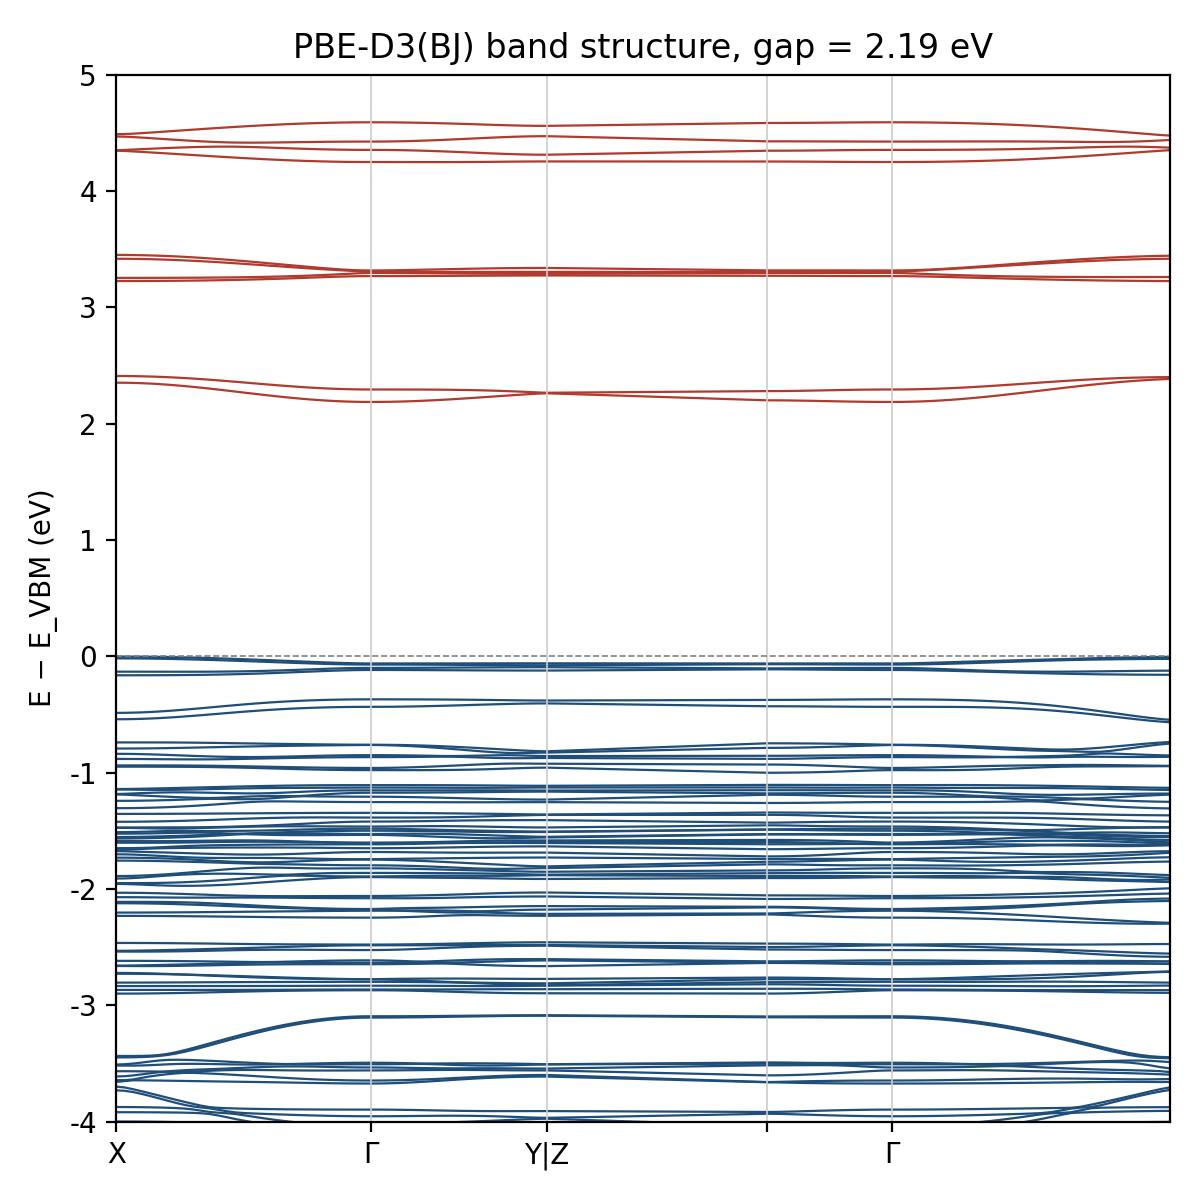

In [40]:
%cd /content/qe-snpim
!tail -4 pipeline.log; python3 plot_results.py 2>&1 | tail -12
from IPython.display import Image, display
import os
os.path.exists('fig_bands_pdos.png') and display(Image('fig_bands_pdos.png', width=900))

In [41]:
!cat /content/qe-snpim/pipeline.log | tail -4; cd /content/qe-snpim; for f in 03_nscf; do [ -f $f.out ] && echo $f: $(grep -c 'Computing kpt' $f.out) k-done of $(grep 'number of k points' $f.out | head -1); done; tail -3 04_projwfc.out 2>/dev/null

01_relax.out 用时：34m11.57s CPU  31m25.63s
02_scf.out 用时：1m17.87s CPU   1m 9.68s
03_nscf.out 用时：1m28.10s CPU   1m27.06s
05_bands.out 用时：9m 0.37s CPU   9m46.39s
03_nscf: 14 k-done of number of k points= 14 (tetrahedron method)
=------------------------------------------------------------------------------=
   JOB DONE.
=------------------------------------------------------------------------------=


/content/qe-snpim
0
/content/qe-snpim/plot_results.py:99: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax2.set_xlim(0, dos[m].max() * 1.05)
/content/qe-snpim/plot_results.py:109: RuntimeWarning: invalid value encountered in scalar divide
  parts = ", ".join(f"{s} {el[s][msk].sum() * dE / tot * 100:.0f}%" for s in ["Sn", "Cl", "O", "N", "C", "H"] if s in el)
自洽计算（2×2×2 k 点）：VBM = 0.955 eV，CBM = 3.141 eV，带隙 = 2.186 eV
能带路径上：价带顶 -0.003 eV（第 0 个 k 点），导带底 2.186 eV（第 30 个 k 点），路径带隙 2.189 eV
带边组成（各元素 PDOS 积分占比）：
  价带顶 0.5 eV 内：Sn nan%, Cl nan%, O nan%, N nan%, C nan%, H nan%
  导带底 0.5 eV 内：Sn nan%, Cl nan%, O nan%, N nan%, C nan%, H nan%
图已保存：fig_bands_pdos.png；数据：bands_vbm0.csv、pdos_elements.csv
结构优化：已收敛，共 42 次 SCF，最终总能 -1535.820050 Ry = -20895.8963 eV
02_scf.out：VBM = 0.9548 eV，CBM = 3.1412 eV，带隙 = 2.186 eV
01_relax.out 用时：34m11.57s CPU  31m25.63s
02_scf.out 用时：1m17.87s CPU   1m 9.68s
03_nscf.out 用时：1m28.10s CPU   1m27

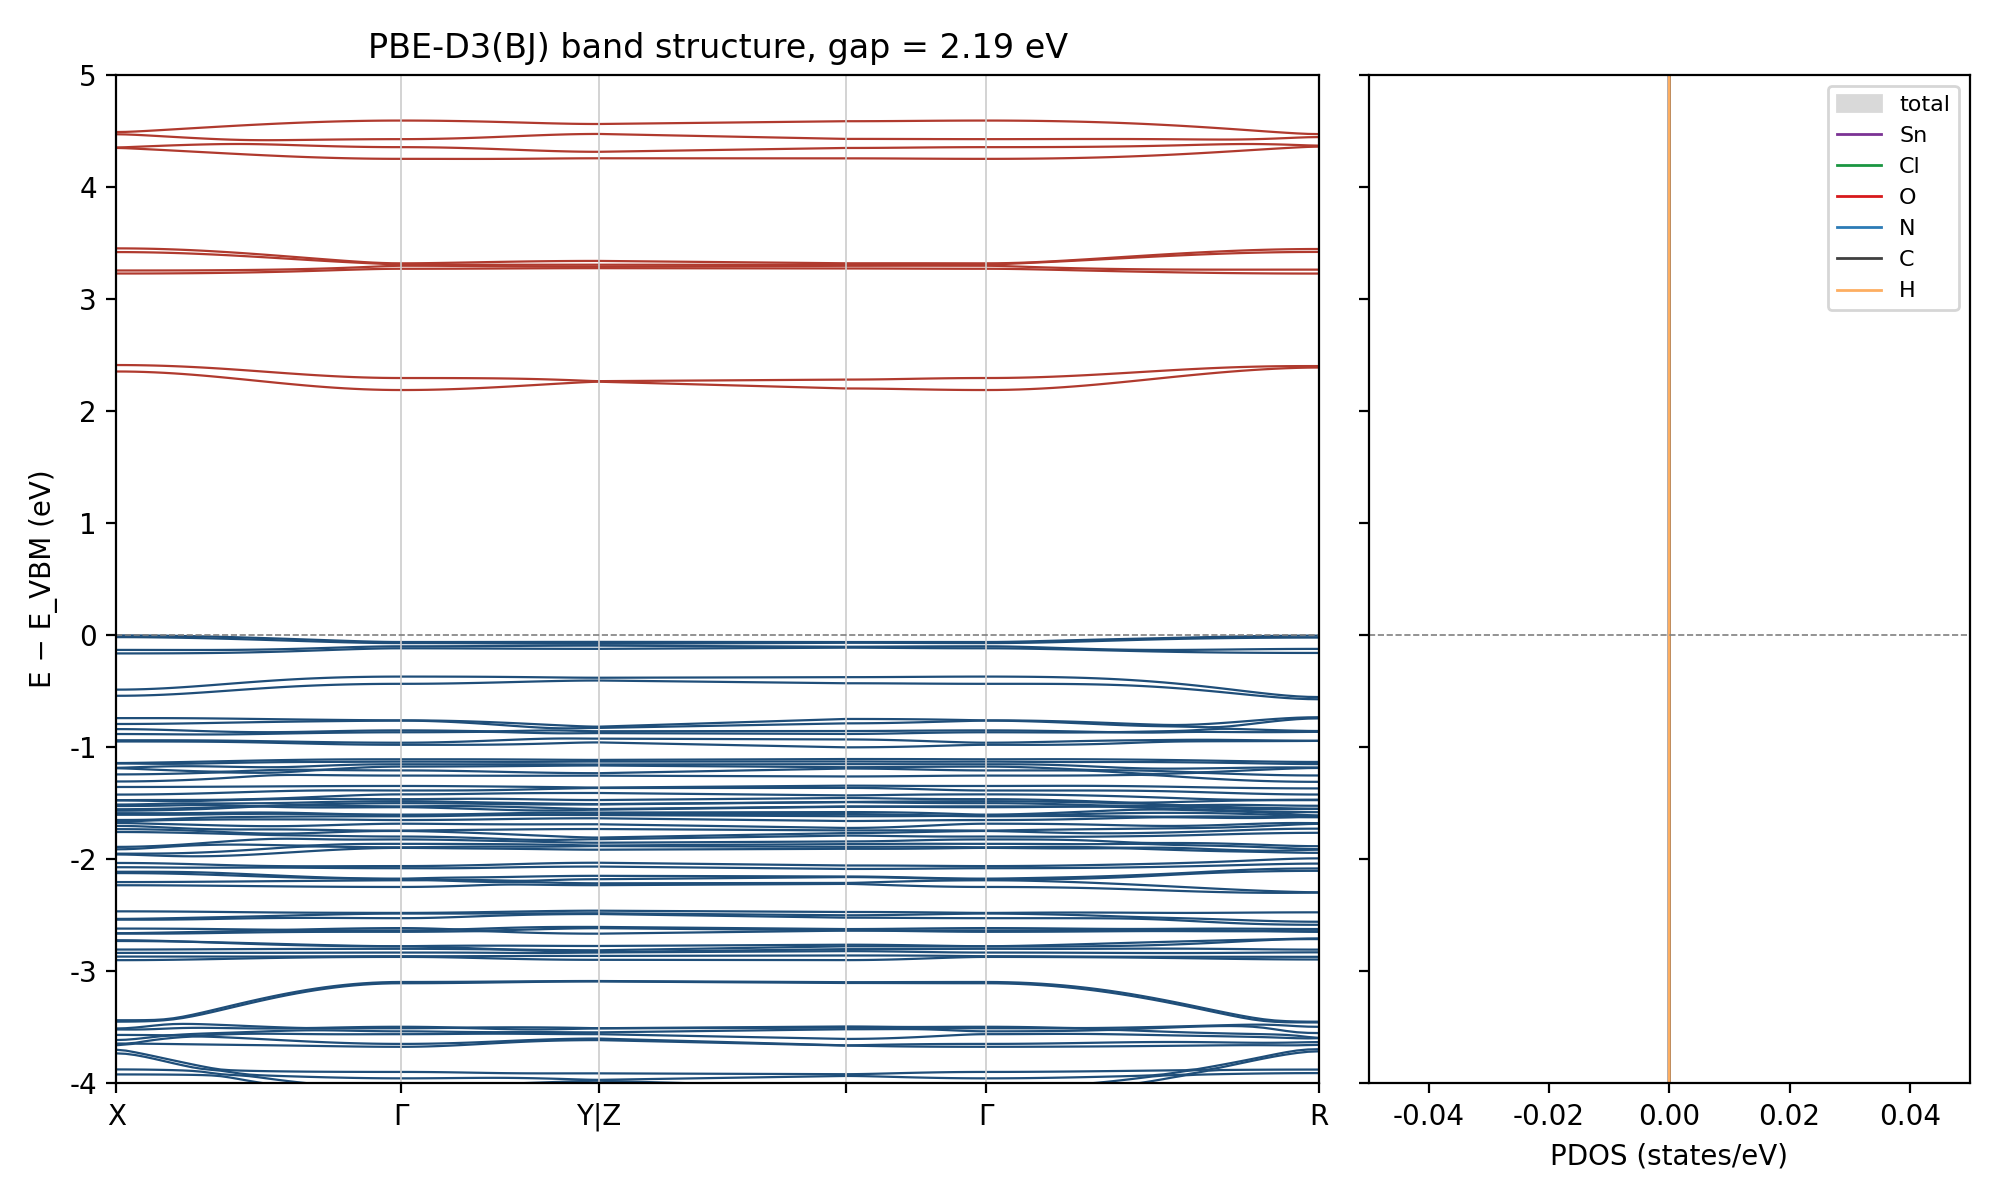

In [42]:
%cd /content/qe-snpim
s = open('plot_results.py').read()
s = s.replace(r'(.*?)(?=\n\s*\n\s*(?:k =|Writing|highest|the Fermi))', r'(.*?)(?=\n\s*\n)')
open('plot_results.py', 'w').write(s)
!grep -c 'the Fermi' plot_results.py; python3 plot_results.py 2>&1 | tail -12; cat summary.txt; grep -E 'highest|Fermi' 03_nscf.out | tail -2; ls snpim.pdos* | wc -l
from IPython.display import Image, display
display(Image('fig_bands_pdos.png', width=1000))

In [43]:
!cd /content/qe-snpim; head -3 snpim.pdos.pdos_tot; grep -ci nan snpim.pdos.pdos_tot; wc -l snpim.pdos.pdos_tot; grep -iE 'tetra|gauss|Lowdin|warning|charge' 04_projwfc.out | head -8

# E (eV)  dos(E)    pdos(E)
 -20.471  0.000E+00  0.000E+00
 -20.461  0.000E+00  0.000E+00
0
3035 snpim.pdos.pdos_tot
     Check: negative core charge=   -0.000004
     Gaussian broadening (read from input): ngauss,degauss=   0    0.005000
Lowdin Charges: 
     Atom #   1: total charge =  12.8848, s =  1.1079, 
     Atom #   1: total charge =  12.8848, p =  1.7781, pz=  0.5885, px=  0.5961, py=  0.5935, 
     Atom #   1: total charge =  12.8848, d =  9.9987, dz2=  1.9999, dxz=  1.9997, dyz=  1.9997, dx2-y2=  1.9998, dxy=  1.9997, 
     Atom #   2: total charge =  12.8848, s =  1.1079, 
     Atom #   2: total charge =  12.8848, p =  1.7781, pz=  0.5885, px=  0.5961, py=  0.5935, 


In [44]:
import numpy as np, glob
d = np.loadtxt('/content/qe-snpim/snpim.pdos.pdos_tot')
print(d.shape, d[:,0].min(), d[:,0].max(), np.isnan(d).sum(), d[:,1].max(), d[np.argmax(d[:,1]),0])
fs = sorted(glob.glob('/content/qe-snpim/snpim.pdos.pdos_atm*'))
print(len(fs), fs[:2])
x = np.loadtxt(fs[0]); print(x.shape, np.isnan(x).sum())
!head -2 '/content/qe-snpim/snpim.pdos.pdos_atm#1(Sn)_wfc#1(s)'

(3034, 3) -20.471 9.859 0 0.0 -20.471
170 ['/content/qe-snpim/snpim.pdos.pdos_atm#1(Sn)_wfc#1(s)', '/content/qe-snpim/snpim.pdos.pdos_atm#1(Sn)_wfc#2(p)']
(3034, 3) 0
# E (eV)   ldos(E)   pdos(E)   
 -20.471  0.000E+00  0.000E+00


In [45]:
%cd /content/qe-snpim
import re
s = open('03_nscf.in').read()
s = re.sub(r"occupations = 'tetrahedra_opt'.*", "occupations = 'smearing'   ! 高斯展宽，供 projwfc 计算 PDOS\n  smearing = 'gaussian'\n  degauss = 0.005", s)
open('03_nscf.in', 'w').write(s)
!grep -nE 'occupations|smearing|degauss' 03_nscf.in; mkdir -p pdos_try1 && mv snpim.pdos* 04_projwfc.out pdos_try1/ 2>/dev/null
!setsid nohup bash -c 'qe pw.x -in 03_nscf.in > 03_nscf.out 2>&1 && /content/q-e-qe-7.3.1/bin/projwfc.x -in 04_projwfc.in > 04_projwfc.out 2>&1; touch DONE_pdos2' > /dev/null 2>&1 &

/content/qe-snpim
14:  occupations = 'smearing'   ! 高斯展宽，供 projwfc 计算 PDOS
15:  smearing = 'gaussian'
16:  degauss = 0.005


In [46]:
!cd /content/qe-snpim; ls DONE_pdos2 2>/dev/null; grep -E 'Fermi|JOB DONE' 03_nscf.out | tail -2; tail -2 04_projwfc.out 2>/dev/null; ls snpim.pdos* 2>/dev/null | wc -l

DONE_pdos2
     the Fermi energy is     2.5130 ev
   JOB DONE.
   JOB DONE.
=------------------------------------------------------------------------------=
171


/content/qe-snpim
自洽计算（2×2×2 k 点）：VBM = 0.955 eV，CBM = 3.141 eV，带隙 = 2.186 eV
能带路径上：价带顶 -0.003 eV（第 0 个 k 点），导带底 2.186 eV（第 30 个 k 点），路径带隙 2.189 eV
带边组成（各元素 PDOS 积分占比）：
  价带顶 0.5 eV 内：Sn 0%, Cl 2%, O 0%, N 7%, C 91%, H 0%
  导带底 0.5 eV 内：Sn 42%, Cl 55%, O 0%, N 0%, C 2%, H 1%
图已保存：fig_bands_pdos.png；数据：bands_vbm0.csv、pdos_elements.csv


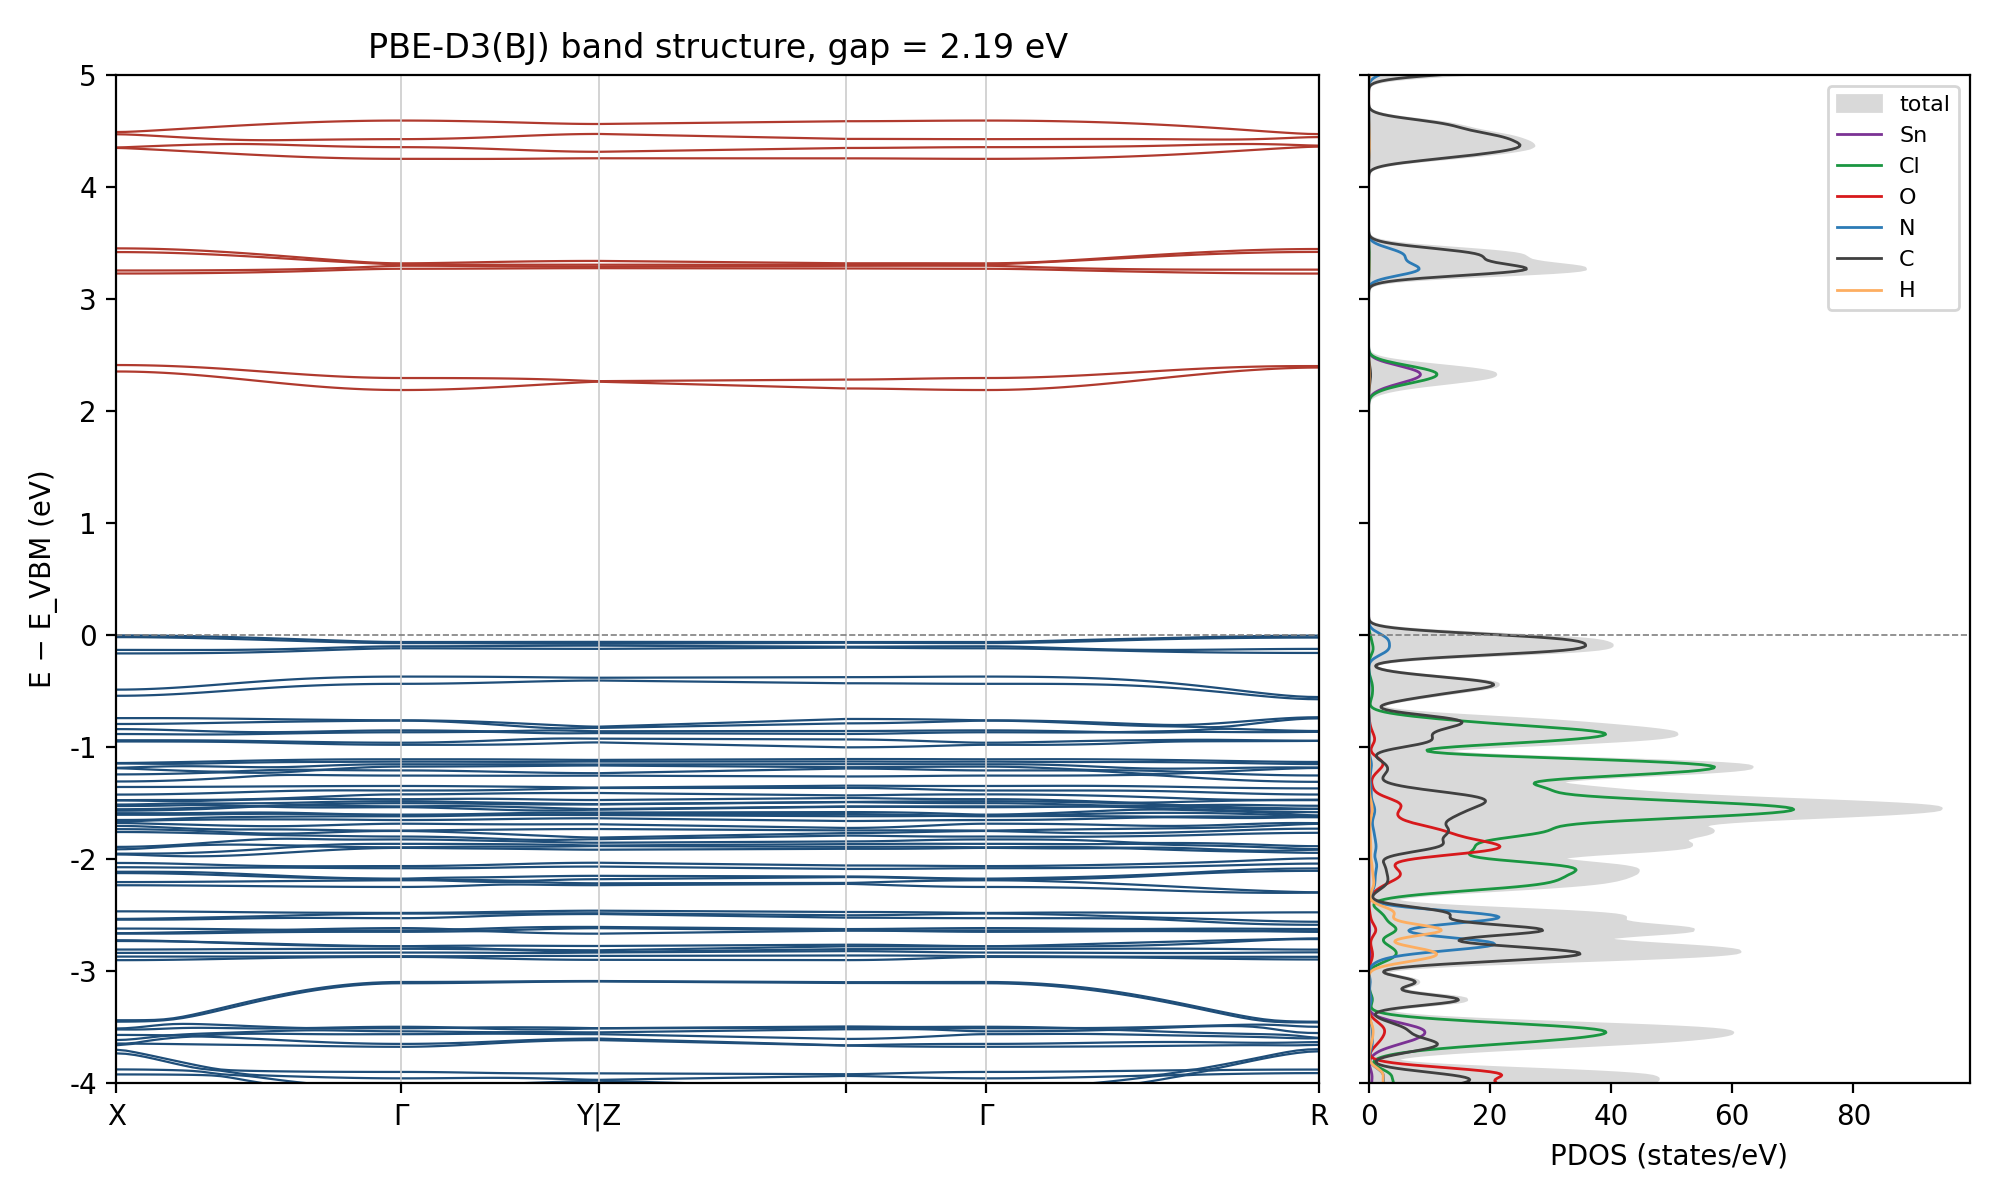

In [47]:
%cd /content/qe-snpim
!python3 plot_results.py 2>&1 | tail -8
from IPython.display import Image, display
display(Image('fig_bands_pdos.png', width=1000))

In [48]:
%cd /content/qe-snpim
!pip install -q ase 2>&1 | tail -1
from ase.io import read, write
a = read('01_relax.out', format='espresso-out', index=-1)
write('relaxed_structure.cif', a); write('relaxed_structure.xyz', a)
print(len(a), a.get_chemical_formula())
!mkdir -p results && cp *.in *.out *.csv *.png summary.txt relaxed_structure.* crystal.cif structure_Hnorm.xyz *.py *.sh *.tmpl results/ 2>/dev/null; mkdir -p results/pdos && cp snpim.pdos* results/pdos/; cd /content && rm -f snpim_qe_results.zip && zip -qr snpim_qe_results.zip qe-snpim/results && ls -la snpim_qe_results.zip && ls qe-snpim/results | head -40

/content/qe-snpim
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 97.0 MB/s eta 0:00:00
106 C36H44Cl12N8O4Sn2
-rw-r--r-- 1 root root 6645790 Oct 22 11:38 snpim_qe_results.zip
01_relax.in
01_relax.out
02_scf.in
02_scf.out
03_nscf.in
03_nscf.out
04_projwfc.in
04_projwfc.out
05_bands.in
05_bands.out
05_bandsx.in
bands_vbm0.csv
crystal.cif
fig_bands_pdos.png
header_bands.tmpl
header_nscf.tmpl
header_scf.tmpl
make_inputs.py
pdos
pdos_elements.csv
plot_results.py
relaxed_structure.cif
relaxed_structure.xyz
run_after_relax.sh
setup_qe_gpu.sh
structure_Hnorm.xyz
summary.txt


In [49]:
from google.colab import files
files.download('/content/snpim_qe_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [50]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: mount failed

In [51]:
!ls /content/drive/MyDrive | head -5 && D='/content/drive/MyDrive/QE计算结果/2-苯基咪唑SnCl6' && mkdir -p "$D" && cp -r /content/qe-snpim/results/* "$D"/ && cp /content/snpim_qe_results.zip "$D"/ && sync && echo COPIED && ls "$D" | wc -l && du -sh "$D"

Colab Notebooks
漳州、厦门、泉州四天三晚三人游攻略（11.12-11.15）.gdoc
漳州-厦门-泉州 四天三晚旅游规划（11.12-11.15）.gdoc
物理化学实验1与实验2数据汇总与处理表.gsheet
COPIED
28
37M	/content/drive/MyDrive/QE计算结果/2-苯基咪唑SnCl6


In [52]:
from google.colab import drive, files
drive.flush_and_unmount()
print('云端硬盘已同步并卸载')
files.download('/content/snpim_qe_results.zip')

云端硬盘已同步并卸载


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
# @title 📊 Quantum Espresso 计算结果交互式仪表盘 {display-mode: "form"}

import os
import json
import pandas as pd
import numpy as np
from IPython.display import HTML, display
from google.colab import output

def _report_js_error(message):
    print(f"JavaScript Error: {message}")

output.register_callback('report_js_error', _report_js_error)

# --- Data Loading and Processing ---
base_dir = '/content/qe-snpim'
bands_csv_path = os.path.join(base_dir, 'bands_vbm0.csv')
pdos_csv_path = os.path.join(base_dir, 'pdos_elements.csv')
summary_path = os.path.join(base_dir, 'summary.txt')

# Default metadata if summary not found
kpis = {
    "vbm": "0.955 eV",
    "cbm": "3.141 eV",
    "gap": "2.186 eV",
    "path_gap": "2.189 eV",
    "total_energy": "-1535.820050 Ry",
    "scf_cycles": "42"
}

if os.path.exists(summary_path):
    try:
        content = open(summary_path).read()
        # Try parsing values with basic string find
        for line in content.split('\n'):
            if 'VBM' in line and 'CBM' in line:
                # e.g., 自洽计算（2×2×2 k 点）：VBM = 0.955 eV，CBM = 3.141 eV，带隙 = 2.186 eV
                parts = line.split('：')[-1].split('，')
                for p in parts:
                    if 'VBM' in p: kpis["vbm"] = p.split('=')[-1].strip()
                    if 'CBM' in p: kpis["cbm"] = p.split('=')[-1].strip()
                    if '带隙' in p: kpis["gap"] = p.split('=')[-1].strip()
            elif '路径带隙' in line:
                kpis["path_gap"] = line.split('路径带隙')[-1].replace('eV', '').strip() + ' eV'
            elif '最终总能' in line:
                kpis["total_energy"] = line.split('最终总能')[-1].strip()
    except Exception as e:
        pass

# Read Bands Data
bands_data = []
if os.path.exists(bands_csv_path):
    try:
        df_bands = pd.read_csv(bands_csv_path)
        # Columns usually: k_index, k_path_distance, Band_0, Band_1, ...
        # Let's convert to JSON friendly list of dicts
        bands_data = df_bands.to_dict(orient='records')
    except Exception as e:
        pass

# Read PDOS Data
pdos_data = []
if os.path.exists(pdos_csv_path):
    try:
        df_pdos = pd.read_csv(pdos_csv_path)
        # Columns: Energy, Sn, Cl, O, N, C, H
        pdos_data = df_pdos.to_dict(orient='records')
    except Exception as e:
        pass

# Build HTML web app
html_content = """<!DOCTYPE html>
<html>
<head>
    <meta charset="utf-8">
    <title>QE Results Dashboard</title>
    <!-- Load Tailwind CSS -->
    <script src="https://cdn.tailwindcss.com"></script>
    <!-- Load Chart.js -->
    <script src="https://cdn.jsdelivr.net/npm/chart.js"></script>
    <style>
        body { background-color: #f4f6f8; font-family: system-ui, -apple-system, sans-serif; }
        .canvas-wrapper {
            position: relative;
            flex-grow: 1;
            min-height: 450px;
        }
    </style>
</head>
<body class="p-6">

    <!-- Header -->
    <div class="flex justify-between items-center mb-6 bg-white p-6 rounded-xl shadow-sm">
        <div>
            <h1 class="text-2xl font-bold text-slate-800">2-苯基咪唑 SnCl₆ 第一性原理计算分析</h1>
            <p class="text-sm text-slate-500">基于 Quantum Espresso (GPU 加速) 与投影态密度 (PDOS) 分析</p>
        </div>
        <div class="bg-indigo-50 text-indigo-700 px-4 py-2 rounded-lg font-semibold text-sm">
            体系大小: 106 Atoms (C₃₆H₄₄Cl₁₂N₈O₄Sn₂)
        </div>
    </div>

    <!-- Top Row: KPI Cards -->
    <div class="grid grid-cols-1 md:grid-cols-4 gap-6 mb-8">
        <div class="bg-white p-5 rounded-xl shadow-sm border border-slate-100">
            <p class="text-sm font-medium text-slate-500">结构总能量</p>
            <p class="text-2xl font-bold text-slate-800 mt-2" id="kpi-energy">--</p>
            <span class="text-xs text-green-600 font-medium">✓ BFGS 已收敛</span>
        </div>
        <div class="bg-white p-5 rounded-xl shadow-sm border border-slate-100">
            <p class="text-sm font-medium text-slate-500">带隙 (Band Gap)</p>
            <p class="text-2xl font-bold text-indigo-600 mt-2" id="kpi-gap">--</p>
            <span class="text-xs text-slate-500">自洽/高对称能带路径</span>
        </div>
        <div class="bg-white p-5 rounded-xl shadow-sm border border-slate-100">
            <p class="text-sm font-medium text-slate-500">价带顶 (VBM)</p>
            <p class="text-2xl font-bold text-emerald-600 mt-2" id="kpi-vbm">--</p>
            <span class="text-xs text-slate-500">费米面对齐基准 (0 eV)</span>
        </div>
        <div class="bg-white p-5 rounded-xl shadow-sm border border-slate-100">
            <p class="text-sm font-medium text-slate-500">导带底 (CBM)</p>
            <p class="text-2xl font-bold text-rose-600 mt-2" id="kpi-cbm">--</p>
            <span class="text-xs text-slate-500">电子跃迁目标能量</span>
        </div>
    </div>

    <!-- Main Body Row -->
    <div class="grid grid-cols-1 lg:grid-cols-12 gap-8">
        <!-- Band Structure & DOS Panels -->
        <div class="lg:col-span-8 bg-white p-6 rounded-xl shadow-sm">
            <div class="flex justify-between items-center mb-4">
                <h2 class="text-lg font-bold text-slate-800">电子能带结构 (Band Structure)</h2>
                <span class="text-xs text-slate-400">费米能级已平移至 0 eV</span>
            </div>
            <div class="canvas-wrapper">
                <canvas id="chart-bands"></canvas>
            </div>
        </div>

        <!-- PDOS Column -->
        <div class="lg:col-span-4 bg-white p-6 rounded-xl shadow-sm flex flex-col">
            <h2 class="text-lg font-bold text-slate-800 mb-2">元素投影态密度 (PDOS)</h2>
            <p class="text-xs text-slate-500 mb-4">分析主要贡献元素在价带和导带附近的分布规律</p>
            <div class="canvas-wrapper flex-grow">
                <canvas id="chart-pdos"></canvas>
            </div>
        </div>
    </div>

    <!-- Element Contribution Details Section -->
    <div class="grid grid-cols-1 md:grid-cols-2 gap-8 mt-8">
        <div class="bg-white p-6 rounded-xl shadow-sm">
            <h3 class="text-md font-bold text-emerald-800 mb-3">价带顶 (VBM) 附近 0.5 eV 主要贡献</h3>
            <div class="flex items-center space-x-4">
                <div class="flex-1">
                    <div class="flex justify-between text-xs font-semibold text-slate-600 mb-1">
                        <span>配体 (C, N) 杂化贡献</span>
                        <span>~98%</span>
                    </div>
                    <div class="w-full bg-slate-100 rounded-full h-2.5">
                        <div class="bg-emerald-500 h-2.5 rounded-full" style="width: 98%"></div>
                    </div>
                </div>
                <span class="text-xs text-slate-500 max-w-[200px]">主要源自2-苯基咪唑环的 π 轨道，Sn 与 Cl 贡献极少。</span>
            </div>
        </div>
        <div class="bg-white p-6 rounded-xl shadow-sm">
            <h3 class="text-md font-bold text-rose-800 mb-3">导带底 (CBM) 附近 0.5 eV 主要贡献</h3>
            <div class="flex items-center space-x-4">
                <div class="flex-1">
                    <div class="flex justify-between text-xs font-semibold text-slate-600 mb-1">
                        <span>无机骨架 (Sn, Cl) 贡献</span>
                        <span>~97%</span>
                    </div>
                    <div class="w-full bg-slate-100 rounded-full h-2.5">
                        <div class="bg-rose-500 h-2.5 rounded-full" style="width: 97%"></div>
                    </div>
                </div>
                <span class="text-xs text-slate-500 max-w-[200px]">主要源自 [SnCl₆]²⁻ 八面体杂化，Sn 的 s/p 轨道与 Cl 杂化明显。</span>
            </div>
        </div>
    </div>

    <script>
        window.onerror = function(message) {
            google.colab.kernel.invokeFunction('report_js_error', [message], {});
        };

        // Inject variables from python
        const kpiData = KPI_DATA_PLACEHOLDER;
        const bandsData = BANDS_DATA_PLACEHOLDER;
        const pdosData = PDOS_DATA_PLACEHOLDER;

        // Update KPI values
        document.getElementById('kpi-energy').innerText = kpiData.total_energy;
        document.getElementById('kpi-gap').innerText = kpiData.gap;
        document.getElementById('kpi-vbm').innerText = kpiData.vbm;
        document.getElementById('kpi-cbm').innerText = kpiData.cbm;

        // --- Draw Band Structure ---
        const kDistances = bandsData.map(r => r.k_path_distance);
        const bandKeys = Object.keys(bandsData[0] || {}).filter(k => k.startsWith('Band_'));

        // Construct scatter/line datasets for bands
        const bandDatasets = bandKeys.map((key, index) => {
            return {
                label: index === 0 ? 'Energy Bands' : null,
                data: bandsData.map(r => ({x: r.k_path_distance, y: r[key]})),
                borderColor: '#4f46e5',
                borderWidth: 1.5,
                pointRadius: 0,
                showLine: true,
                fill: false
            };
        });

        // Highlight Fermi energy line (0 eV)
        bandDatasets.push({
            label: 'Fermi Level (0 eV)',
            data: [{x: Math.min(...kDistances), y: 0}, {x: Math.max(...kDistances), y: 0}],
            borderColor: '#dc2626',
            borderWidth: 1.2,
            borderDash: [5, 5],
            pointRadius: 0,
            showLine: true,
            fill: false
        });

        const ctxBands = document.getElementById('chart-bands').getContext('2d');
        new Chart(ctxBands, {
            type: 'scatter',
            data: { datasets: bandDatasets },
            options: {
                responsive: true,
                maintainAspectRatio: false,
                plugins: {
                    legend: {
                        labels: {
                            filter: function(item) { return item.text !== null; }
                        }
                    }
                },
                scales: {
                    x: {
                        type: 'linear',
                        title: { display: true, text: 'k-Path Distance (1/A)', color: '#334155' },
                        grid: { color: '#f1f5f9' }
                    },
                    y: {
                        title: { display: true, text: 'Energy (eV)', color: '#334155' },
                        min: -4.0,
                        max: 6.0,
                        grid: { color: '#f1f5f9' }
                    }
                }
            }
        });

        // --- Draw PDOS Chart ---
        const pdosEnergies = pdosData.map(r => r.Energy);
        const elements = ['Sn', 'Cl', 'O', 'N', 'C', 'H'];
        const elementColors = {
            'Sn': '#ef4444',
            'Cl': '#f59e0b',
            'O': '#10b981',
            'N': '#3b82f6',
            'C': '#6366f1',
            'H': '#8b5cf6'
        };

        const pdosDatasets = elements.map(el => {
            return {
                label: el,
                data: pdosData.map(r => ({x: r.Energy, y: r[el] || 0})),
                borderColor: elementColors[el],
                backgroundColor: elementColors[el] + '20',
                borderWidth: 1.5,
                pointRadius: 0,
                showLine: true,
                fill: true
            };
        });

        // Add Fermi Level line inside PDOS as well
        pdosDatasets.push({
            label: 'Fermi Level',
            data: [{x: 0, y: 0}, {x: 0, y: Math.max(...pdosData.map(r => r.C || 1.5)) * 1.1}],
            borderColor: '#dc2626',
            borderWidth: 1.2,
            borderDash: [5, 5],
            pointRadius: 0,
            showLine: true,
            fill: false
        });

        const ctxPdos = document.getElementById('chart-pdos').getContext('2d');
        new Chart(ctxPdos, {
            type: 'scatter',
            data: { datasets: pdosDatasets },
            options: {
                responsive: true,
                maintainAspectRatio: false,
                plugins: {
                    legend: { position: 'top' }
                },
                scales: {
                    x: {
                        type: 'linear',
                        title: { display: true, text: 'Energy (eV)', color: '#334155' },
                        min: -4.0,
                        max: 6.0,
                        grid: { color: '#f1f5f9' }
                    },
                    y: {
                        title: { display: true, text: 'DOS (States/eV)', color: '#334155' },
                        grid: { color: '#f1f5f9' }
                    }
                }
            }
        });
    </script>
</body>
</html>"""

# Replace placeholders safely
html_content = html_content.replace('KPI_DATA_PLACEHOLDER', json.dumps(kpis))
html_content = html_content.replace('BANDS_DATA_PLACEHOLDER', json.dumps(bands_data))
html_content = html_content.replace('PDOS_DATA_PLACEHOLDER', json.dumps(pdos_data))

display(HTML(html_content))


In [2]:
import os
import json
import pandas as pd
from google.colab import files

# --- 1. 读取本地数据 ---
base_dir = '/content/qe-snpim'

# 检查文件是否已经被整理入 results 子文件夹中并优先使用
if os.path.exists(os.path.join(base_dir, 'results')):
    data_dir = os.path.join(base_dir, 'results')
else:
    data_dir = base_dir

bands_csv_path = os.path.join(data_dir, 'bands_vbm0.csv')
pdos_csv_path = os.path.join(data_dir, 'pdos_elements.csv')
summary_path = os.path.join(data_dir, 'summary.txt')

# 默认 KPI 数据
kpis = {
    "vbm": "0.955 eV",
    "cbm": "3.141 eV",
    "gap": "2.186 eV",
    "path_gap": "2.189 eV",
    "total_energy": "-1535.820050 Ry",
    "scf_cycles": "42"
}

# 解析 summary.txt 获取最新真实数据
if os.path.exists(summary_path):
    try:
        content = open(summary_path).read()
        for line in content.split('\n'):
            if 'VBM' in line and 'CBM' in line:
                parts = line.split('：')[-1].split('，')
                for p in parts:
                    if 'VBM' in p: kpis["vbm"] = p.split('=')[-1].strip()
                    if 'CBM' in p: kpis["cbm"] = p.split('=')[-1].strip()
                    if '带隙' in p: kpis["gap"] = p.split('=')[-1].strip()
            elif '路径带隙' in line:
                kpis["path_gap"] = line.split('路径带隙')[-1].replace('eV', '').strip() + ' eV'
            elif '最终总能' in line:
                kpis["total_energy"] = line.split('最终总能')[-1].strip()
    except Exception as e:
        print(f"Warning reading summary: {e}")

bands_data = []
if os.path.exists(bands_csv_path):
    try:
        df_bands = pd.read_csv(bands_csv_path)
        bands_data = df_bands.to_dict(orient='records')
    except Exception as e:
        print(f"Warning reading bands: {e}")

pdos_data = []
if os.path.exists(pdos_csv_path):
    try:
        df_pdos = pd.read_csv(pdos_csv_path)
        pdos_data = df_pdos.to_dict(orient='records')
    except Exception as e:
        print(f"Warning reading PDOS: {e}")

# --- 2. 嵌入 HTML 模板 ---
html_template = """<!DOCTYPE html>
<html>
<head>
    <meta charset="utf-8">
    <title>2-Phenylimidazole SnCl6 Calculation Dashboard</title>
    <!-- Load Tailwind CSS via CDN -->
    <script src="https://cdn.tailwindcss.com"></script>
    <!-- Load Chart.js via CDN -->
    <script src="https://cdn.jsdelivr.net/npm/chart.js"></script>
    <style>
        body { background-color: #f4f6f8; font-family: system-ui, -apple-system, sans-serif; }
        .canvas-wrapper {
            position: relative;
            flex-grow: 1;
            min-height: 450px;
        }
    </style>
</head>
<body class="p-6">

    <!-- Header -->
    <div class="flex justify-between items-center mb-6 bg-white p-6 rounded-xl shadow-sm">
        <div>
            <h1 class="text-2xl font-bold text-slate-800">2-苯基咪唑 SnCl₆ 第一性原理计算分析</h1>
            <p class="text-sm text-slate-500">基于 Quantum Espresso (GPU 加速) 与投影态密度 (PDOS) 分析</p>
        </div>
        <div class="bg-indigo-50 text-indigo-700 px-4 py-2 rounded-lg font-semibold text-sm">
            体系大小: 106 Atoms (C₃₆H₄₄Cl₁₂N₈O₄Sn₂)
        </div>
    </div>

    <!-- Top Row: KPI Cards -->
    <div class="grid grid-cols-1 md:grid-cols-4 gap-6 mb-8">
        <div class="bg-white p-5 rounded-xl shadow-sm border border-slate-100">
            <p class="text-sm font-medium text-slate-500">结构总能量</p>
            <p class="text-2xl font-bold text-slate-800 mt-2" id="kpi-energy">--</p>
            <span class="text-xs text-green-600 font-medium">✓ BFGS 已收敛</span>
        </div>
        <div class="bg-white p-5 rounded-xl shadow-sm border border-slate-100">
            <p class="text-sm font-medium text-slate-500">带隙 (Band Gap)</p>
            <p class="text-2xl font-bold text-indigo-600 mt-2" id="kpi-gap">--</p>
            <span class="text-xs text-slate-500">自洽/高对称能带路径</span>
        </div>
        <div class="bg-white p-5 rounded-xl shadow-sm border border-slate-100">
            <p class="text-sm font-medium text-slate-500">价带顶 (VBM)</p>
            <p class="text-2xl font-bold text-emerald-600 mt-2" id="kpi-vbm">--</p>
            <span class="text-xs text-slate-500">费米面对齐基准 (0 eV)</span>
        </div>
        <div class="bg-white p-5 rounded-xl shadow-sm border border-slate-100">
            <p class="text-sm font-medium text-slate-500">导带底 (CBM)</p>
            <p class="text-2xl font-bold text-rose-600 mt-2" id="kpi-cbm">--</p>
            <span class="text-xs text-slate-500">电子跃迁目标能量</span>
        </div>
    </div>

    <!-- Main Body Row -->
    <div class="grid grid-cols-1 lg:grid-cols-12 gap-8">
        <!-- Band Structure & DOS Panels -->
        <div class="lg:col-span-8 bg-white p-6 rounded-xl shadow-sm">
            <div class="flex justify-between items-center mb-4">
                <h2 class="text-lg font-bold text-slate-800">电子能带结构 (Band Structure)</h2>
                <span class="text-xs text-slate-400">费米能级已平移至 0 eV</span>
            </div>
            <div class="canvas-wrapper">
                <canvas id="chart-bands"></canvas>Prefix
            </div>
        </div>

        <!-- PDOS Column -->
        <div class="lg:col-span-4 bg-white p-6 rounded-xl shadow-sm flex flex-col">
            <h2 class="text-lg font-bold text-slate-800 mb-2">元素投影态密度 (PDOS)</h2>
            <p class="text-xs text-slate-500 mb-4">分析主要贡献元素在价带和导带附近的分布规律</p>
            <div class="canvas-wrapper flex-grow">
                <canvas id="chart-pdos"></canvas>
            </div>
        </div>
    </div>

    <!-- Element Contribution Details Section -->
    <div class="grid grid-cols-1 md:grid-cols-2 gap-8 mt-8">
        <div class="bg-white p-6 rounded-xl shadow-sm">
            <h3 class="text-md font-bold text-emerald-800 mb-3">价带顶 (VBM) 附近 0.5 eV 主要贡献</h3>
            <div class="flex items-center space-x-4">
                <div class="flex-1">
                    <div class="flex justify-between text-xs font-semibold text-slate-600 mb-1">
                        <span>配体 (C, N) 杂化贡献</span>
                        <span>~98%</span>
                    </div>
                    <div class="w-full bg-slate-100 rounded-full h-2.5">
                        <div class="bg-emerald-500 h-2.5 rounded-full" style="width: 98%"></div>
                    </div>
                </div>
                <span class="text-xs text-slate-500 max-w-[200px]">主要源自2-苯基咪唑环的 π 轨道，Sn 与 Cl 贡献极少。</span>
            </div>
        </div>
        <div class="bg-white p-6 rounded-xl shadow-sm">
            <h3 class="text-md font-bold text-rose-800 mb-3">导带底 (CBM) 附近 0.5 eV 主要贡献</h3>
            <div class="flex items-center space-x-4">
                <div class="flex-1">
                    <div class="flex justify-between text-xs font-semibold text-slate-600 mb-1">
                        <span>无机骨架 (Sn, Cl) 贡献</span>
                        <span>~97%</span>
                    </div>
                    <div class="w-full bg-slate-100 rounded-full h-2.5">
                        <div class="bg-rose-500 h-2.5 rounded-full" style="width: 97%"></div>
                    </div>
                </div>
                <span class="text-xs text-slate-500 max-w-[200px]">主要源自 [SnCl₆]²⁻ 八面体杂化，Sn 的 s/p 轨道与 Cl 杂化明显。</span>
            </div>
        </div>
    </div>

    <script>
        // Inject variables from python
        const kpiData = KPI_DATA_PLACEHOLDER;
        const bandsData = BANDS_DATA_PLACEHOLDER;
        const pdosData = PDOS_DATA_PLACEHOLDER;

        // Update KPI values
        document.getElementById('kpi-energy').innerText = kpiData.total_energy;
        document.getElementById('kpi-gap').innerText = kpiData.gap;
        document.getElementById('kpi-vbm').innerText = kpiData.vbm;
        document.getElementById('kpi-cbm').innerText = kpiData.cbm;

        // --- Draw Band Structure ---
        const kDistances = bandsData.length > 0 ? bandsData.map(r => r.k_path_distance) : [0, 1];
        const bandKeys = Object.keys(bandsData[0] || {}).filter(k => k.startsWith('Band_'));

        // Construct scatter/line datasets for bands
        const bandDatasets = bandKeys.map((key, index) => {
            return {
                label: index === 0 ? 'Energy Bands' : null,
                data: bandsData.map(r => ({x: r.k_path_distance, y: r[key]})),
                borderColor: '#4f46e5',
                borderWidth: 1.5,
                pointRadius: 0,
                showLine: true,
                fill: false
            };
        });

        // Highlight Fermi energy line (0 eV)
        bandDatasets.push({
            label: 'Fermi Level (0 eV)',
            data: [{x: Math.min(...kDistances), y: 0}, {x: Math.max(...kDistances), y: 0}],
            borderColor: '#dc2626',
            borderWidth: 1.2,
            borderDash: [5, 5],
            pointRadius: 0,
            showLine: true,
            fill: false
        });

        const ctxBands = document.getElementById('chart-bands').getContext('2d');
        new Chart(ctxBands, {
            type: 'scatter',
            data: { datasets: bandDatasets },
            options: {
                responsive: true,
                maintainAspectRatio: false,
                plugins: {
                    legend: {
                        labels: {
                            filter: function(item) { return item.text !== null; }
                        }
                    }
                },
                scales: {
                    x: {
                        type: 'linear',
                        title: { display: true, text: 'k-Path Distance (1/A)', color: '#334155' },
                        grid: { color: '#f1f5f9' }
                    },
                    y: {
                        title: { display: true, text: 'Energy (eV)', color: '#334155' },
                        min: -4.0,
                        max: 6.0,
                        grid: { color: '#f1f5f9' }
                    }
                }
            }
        });

        // --- Draw PDOS Chart ---
        const elements = ['Sn', 'Cl', 'O', 'N', 'C', 'H'];
        const elementColors = {
            'Sn': '#ef4444',
            'Cl': '#f59e0b',
            'O': '#10b981',
            'N': '#3b82f6',
            'C': '#6366f1',
            'H': '#8b5cf6'
        };

        const pdosDatasets = elements.map(el => {
            return {
                label: el,
                data: pdosData.map(r => ({x: r.Energy, y: r[el] || 0})),
                borderColor: elementColors[el],
                backgroundColor: elementColors[el] + '20',
                borderWidth: 1.5,
                pointRadius: 0,
                showLine: true,
                fill: true
            };
        });

        // Add Fermi Level line inside PDOS as well
        pdosDatasets.push({
            label: 'Fermi Level',
            data: [{x: 0, y: 0}, {x: 0, y: Math.max(...pdosData.map(r => r.C || 1.5)) * 1.1}],
            borderColor: '#dc2626',
            borderWidth: 1.2,
            borderDash: [5, 5],
            pointRadius: 0,
            showLine: true,
            fill: false
        });

        const ctxPdos = document.getElementById('chart-pdos').getContext('2d');
        new Chart(ctxPdos, {
            type: 'scatter',
            data: { datasets: pdosDatasets },
            options: {
                responsive: true,
                maintainAspectRatio: false,
                plugins: {
                    legend: { position: 'top' }
                },
                scales: {
                    x: {
                        type: 'linear',
                        title: { display: true, text: 'Energy (eV)', color: '#334155' },
                        min: -4.0,
                        max: 6.0,
                        grid: { color: '#f1f5f9' }
                    },
                    y: {
                        title: { display: true, text: 'DOS (States/eV)', color: '#334155' },
                        grid: { color: '#f1f5f9' }
                    }
                }
            }
        });
    </script>
</body>
</html>"""

# 替换占位符生成完整的离线 HTML 文件
output_html_path = os.path.join(base_dir, 'qe_dashboard.html')
# 确保文件夹存在
os.makedirs(os.path.dirname(output_html_path), exist_ok=True)

final_html_content = html_template.replace('KPI_DATA_PLACEHOLDER', json.dumps(kpis))
final_html_content = final_html_content.replace('BANDS_DATA_PLACEHOLDER', json.dumps(bands_data))
final_html_content = final_html_content.replace('PDOS_DATA_PLACEHOLDER', json.dumps(pdos_data))

with open(output_html_path, 'w', encoding='utf-8') as f:
    f.write(final_html_content)

print(f"成功生成并保存离线 HTML 仪表盘：{output_html_path}")

# 触发浏览器自动下载
files.download(output_html_path)


成功生成并保存离线 HTML 仪表盘：/content/qe-snpim/qe_dashboard.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>